# Wilson-Cowan Neural Network Simulation and Inference

This notebook demonstrates the robustness of the inference method to model-mismatch by generating synthetic data from a highly non-linear neural rate model (Wilson-Cowan) and successfully inferring its topology using the SDE-based global parameter MCMC engine.


In [1]:
import numpy as np
import networkx as nx
import graph_tool.all as gt
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit
import sys
import os

sys.path.append(os.path.abspath('.'))
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import compute_reconstruction_metrics
from gene_expr import GeneExprBlockState


## 1. Simulate the Wilson-Cowan Network

We generate a 10-node directed Erdos-Renyi graph and simulate its dynamics using the Wilson-Cowan ODEs. We use 20 independent trials to simulate transient responses to stimuli, providing the inference algorithm with a rich dynamical dataset.


Simulating Wilson-Cowan Neural Network (N=10)...
Generated 570 transition pairs with dt=0.1


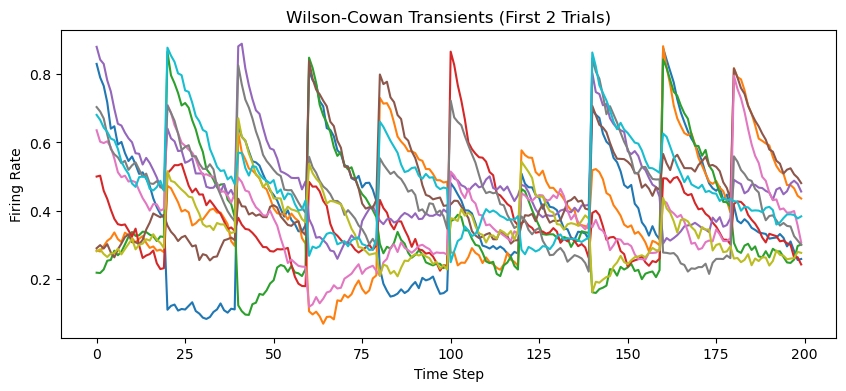

In [12]:
np.random.seed(42)
N = 10
p_edge = 0.15

# Generate Ground Truth Graph
G_true = nx.erdos_renyi_graph(n=N, p=p_edge, directed=True, seed=42)
W_true = nx.to_numpy_array(G_true)
# Randomly assign +3.0 (excitatory) or -3.0 (inhibitory) to edges
signs = np.random.choice([-1.0, 1.0], size=(N, N))
true_weights = np.random.uniform(0.5, 1.5, size=(N, N))
W_true = W_true * signs * true_weights

# Simulation parameters
tau = 2.0         
I = -1.5          
sigma = 0.05      # Low noise to preserve signal
dt_sim = 0.01
steps_per_trial = 200  # 5 time units per trial
num_trials = 30        # 20 different initial conditions
subsample = 10         # dt_infer = 0.1

print(f"Simulating Wilson-Cowan Neural Network (N={N})...")
pairs = []
trajectories = []

for trial in range(num_trials):
    x = np.random.uniform(0.1, 0.9, size=N)
    trial_traj = []
    
    for step in range(steps_per_trial):
        net_input = W_true @ x + I
        activation = expit(net_input)
        dx = (-x / tau + (1 - x) * activation) * dt_sim
        noise = sigma * np.sqrt(dt_sim) * np.random.randn(N)
        
        x = x + dx + noise
        x = np.clip(x, 0.01, 0.99)
        
        if step % subsample == 0:
            trial_traj.append(x.copy())
            
    # Add pairs for this trial
    for i in range(len(trial_traj) - 1):
        pairs.append(np.column_stack([trial_traj[i], trial_traj[i+1]]))
    trajectories.extend(trial_traj)

trajectories = np.array(trajectories)
dt_infer = dt_sim * subsample
print(f"Generated {len(pairs)} transition pairs with dt={dt_infer}")

# Plot transients
plt.figure(figsize=(10, 4))
plt.plot(trajectories[:200]) # Plot first few trials
plt.title('Wilson-Cowan Transients (First 2 Trials)')
plt.xlabel('Time Step')
plt.ylabel('Firing Rate')
plt.show()


## 2. Run MCMC Inference

We now feed the dataset into the standard `GeneExprBlockState` engine. Even though the generating physics differ significantly from the internal SDE solver, we expect the engine to capture the primary topological constraints.


In [17]:
g_init = gt.Graph(directed=True)
g_init.add_vertex(N)
g_init.add_edge(0, 1)

# Initial theta: [log(decay), log(V), log(noise)]
initial_theta = [np.log(1/tau), np.log(1.0), np.log(0.01)]

print("Initializing Inference Engine...")
state = GeneExprBlockState(pairs, dt=dt_infer, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta, self_loops=False)

print("Running Burn-in (100 sweeps)...")
state = run_burn_in(state, n_burnin=100, theta_mode="global", beta=1.0)

print("Running Posterior Sampling (200 sweeps)...")
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=100, delta_k=1, theta_mode="global", beta=1.5)

edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
W_inferred = W_ensemble[-1]


Initializing Inference Engine...
Running Burn-in (100 sweeps)...

--- PHASE 1: Equilibration (100 sweeps) ---
Burn-in Sweep  1/100: Entropy = -13854.1128 (dS_topo = -5708.7105, dS_param = -700.3243, moves = 5815)
Burn-in Sweep 10/100: Entropy = -13930.9043 (dS_topo =  18.7666, dS_param =  -2.6944, moves = 4604)
Burn-in Sweep 20/100: Entropy = -14123.7082 (dS_topo =  12.9510, dS_param =  -7.0951, moves = 7160)
Burn-in Sweep 30/100: Entropy = -14105.5800 (dS_topo =  13.4026, dS_param =  -6.6816, moves = 5681)
Burn-in Sweep 40/100: Entropy = -14199.9098 (dS_topo = -43.0018, dS_param =  -2.3282, moves = 5359)
Burn-in Sweep 50/100: Entropy = -14093.5908 (dS_topo =  35.1911, dS_param =  -0.0274, moves = 5445)
Burn-in Sweep 60/100: Entropy = -14045.0633 (dS_topo =  68.0265, dS_param =  -1.0287, moves = 5373)
Burn-in Sweep 70/100: Entropy = -14266.7131 (dS_topo =  -5.5369, dS_param =  -1.7707, moves = 5553)
Burn-in Sweep 80/100: Entropy = -14348.6285 (dS_topo = -73.5365, dS_param =  -0.0154, m

## 3. Evaluation and Metrics

Finally, we calculate the F1-Score, True Positive Rate, and Structural Hamming Distance to evaluate topological reconstruction, and visualize the true vs. inferred adjacency matrices.


--- RESULTS ---
F1-Score: 0.357
TPR (Recall): 0.385 | FPR: 0.130 | Precision: 0.333
SHD: 18
Sign Accuracy: 0.820


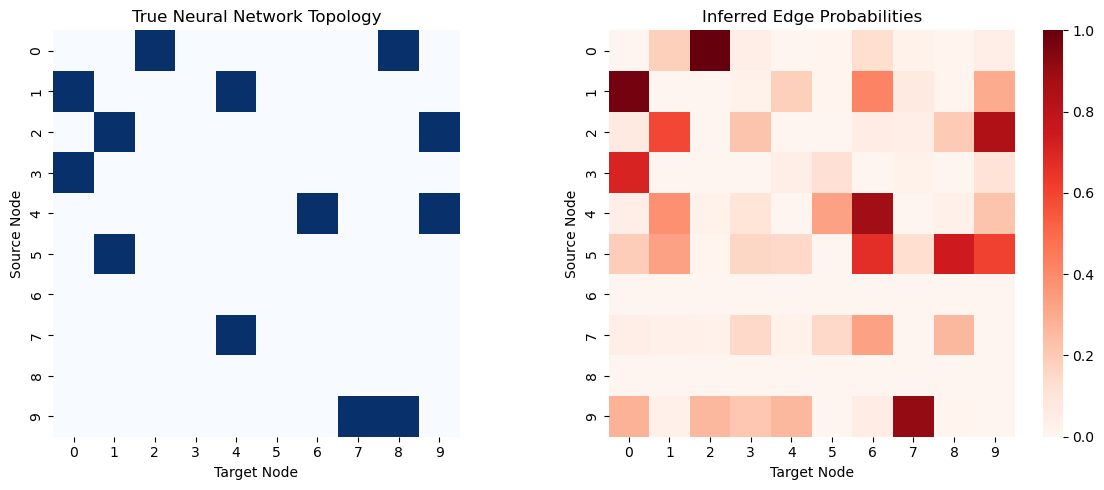

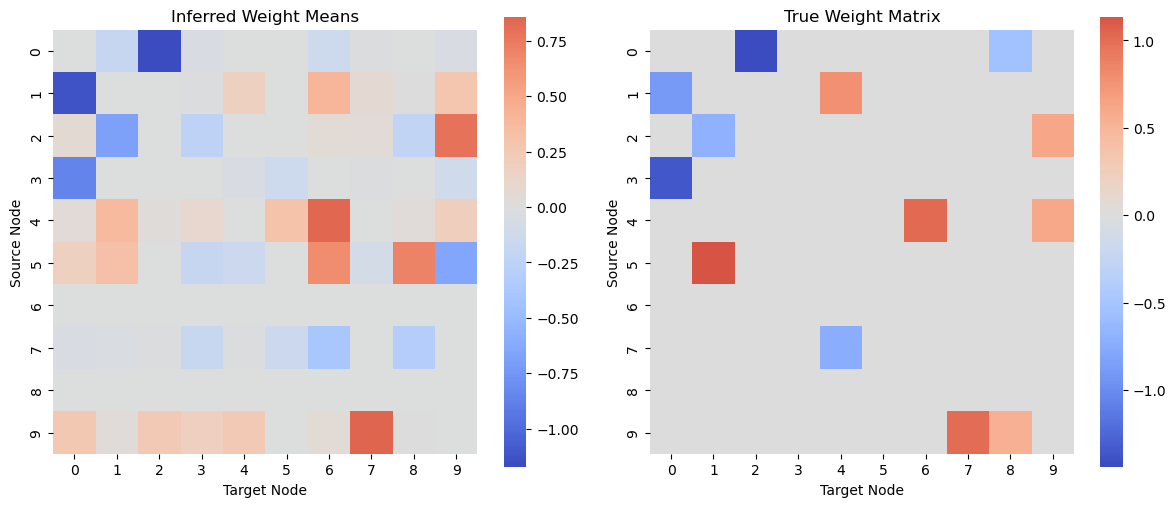

In [18]:
metrics = compute_reconstruction_metrics(W_true, W_inferred)
print("--- RESULTS ---")
print(f"F1-Score: {metrics['F1-Score']:.3f}")
print(f"TPR (Recall): {metrics['TPR (Recall)']:.3f} | FPR: {metrics['FPR']:.3f} | Precision: {metrics['Precision']:.3f}")
print(f"SHD: {metrics['SHD']}")
# sign accuracy
true_signs = np.sign(W_true)
inferred_signs = np.sign(W_inferred)
sign_accuracy = np.sum(true_signs == inferred_signs) / (N * N)
print(f"Sign Accuracy: {sign_accuracy:.3f}")

# Plot Probability Matrix vs True Adjacency
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(np.abs(W_true) > 0, ax=axes[0], cmap="Blues", cbar=False, square=True)
axes[0].set_title("True Neural Network Topology")
axes[0].set_xlabel("Target Node")
axes[0].set_ylabel("Source Node")

sns.heatmap(edge_probabilities, ax=axes[1], cmap="Reds", vmin=0, vmax=1.0, square=True)
axes[1].set_title("Inferred Edge Probabilities")
axes[1].set_xlabel("Target Node")
axes[1].set_ylabel("Source Node")

plt.tight_layout()
plt.show()

# Plot Weight Mean vs True Weights
_, ax = plt.subplots(1,2,figsize=(12, 5))
sns.heatmap(weight_mean*edge_probabilities, cmap="coolwarm", square=True, center=0, ax=ax[0])
ax[0].set_title("Inferred Weight Means")
ax[0].set_xlabel("Target Node")
ax[0].set_ylabel("Source Node")

sns.heatmap(W_true, cmap="coolwarm", square=True, center=0, ax=ax[1])
ax[1].set_title("True Weight Matrix")
ax[1].set_xlabel("Target Node")
ax[1].set_ylabel("Source Node")

plt.tight_layout()
plt.show()
